# 06 — The operating boundary: where the study area came from, and what is inside it

**Almaty SuperSki terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

This release has one study area: a boundary drawn by hand over satellite
imagery. Everything else is a working window around it.

Getting there took two retractions. The first release picked a 69 km² rectangle
around the plateau by assertion. The second derived a 125 km² rectangle from the
control points on the operator's general plan — better placed, but still a
rectangle, and only 14 % of it was the site. Both reached about 3 km north of
where any skiing is planned, over the dacha belt below the plateau, and both
reported medians over that ground as if they described the project. Both are
withdrawn, and so are the two synthetic 1,022 ha footprints notebook 05 used to
carry. What remains is the drawn boundary and a rectangle that exists only to
give it a margin.

Everything here is computed by `src/pipeline_operating_area.py`. This notebook
calls that module rather than reimplementing it, so there is exactly one
implementation of every number and the PDF, the tables and this page can never
drift apart. Redraw `qgis/operating_area.geojson`, re-run, and every figure
below follows.

> **This boundary is not official.** Kazakh Tourism Development states a
> territory of 1,022 ha and has published no coordinates. Nothing here is
> commissioned by, affiliated with or endorsed by any operator or public body.

In [1]:
import os

os.environ["KZ_AREA"] = "superski"        # must be set before importing config

import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

import operating_area as OA
import pipeline_operating_area as PL
import ski_terrain as ST
import viz
from config import (AOI_BBOX_WGS84, AREA_LABEL, AREA_NOTE, HORIZON_N_AZIMUTH,
                    INTERIM, MIN_VALID_OBS, OUT_PNG, OUT_TAB, PROJECT_AREA_HA,
                    PROJECT_GREEN_BLUE_SHARE, PROJECT_GREEN_BLUE_SHARE_PRESS,
                    PROJECT_LIFTS, PROJECT_LIFTS_PRESS, PROJECT_PISTE_KM,
                    PROJECT_SNOWMAKING_SHARE, STUDY_AREAS, SUN_HOUR_STEP_MIN)
from grids import DEM_GRID

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

print(f"area        : {AREA_LABEL}")
print(f"grid        : {DEM_GRID.width} x {DEM_GRID.height} @ {DEM_GRID.res:.0f} m "
      f"= {DEM_GRID.area_km2:.0f} km2, {DEM_GRID.crs}")
print(f"horizon     : {HORIZON_N_AZIMUTH} azimuths ({360//HORIZON_N_AZIMUTH} deg)")
print(f"sun step    : {SUN_HOUR_STEP_MIN} min")

area        : Almaty SuperSki - the drawn operating boundary and its working window
grid        : 292 x 267 @ 30 m = 70 km2, EPSG:32643
horizon     : 72 azimuths (5 deg)
sun step    : 10 min


## 1. Why the study area moved, twice

The operator's general plan is a perspective panorama — no projection, no scale
bar, no graticule — so **nothing is traced from it**. What it carries is *named
features*, and those can be located independently in OpenStreetMap. Those seven
points are what showed the first rectangle was in the wrong place; they are kept
here because they are the evidence, not because the rectangle they produced
survived.

In [2]:
CONTROL_POINTS = {
    "MEDEU":                    (77.05757, 43.15944, "OSM place, suburb"),
    "KOKGAILAU PLATEAU 1951 m":  (77.00433, 43.14239, "project reference point"),
    "THREE BROTHERS ROCKS":     (77.01337, 43.12687, "OSM peak «Три брата», 2860 m"),
    "MOUNTAIN KUMBEL 3250 m":   (77.03130, 43.11934, "OSM peak «Qumbel», 3221 m"),
    "KUMBELTAU RANGE 3500 m":   (77.04056, 43.08490, "OSM peak «Qumbeltau», 3618 m"),
    "KIMASAR":                  (77.08281, 43.17116, "OSM saddle «Кімасар», 2080 m"),
    "SHYMBULAK":                (77.09312, 43.12275, "OSM landuse=winter_sports"),
}
# The two retired rectangles, kept as literals so the record can be checked.
# Neither is a study area any more; neither is in config.py.
RETIRED = {
    "1st release — author's 69 km² box": (76.960, 43.105, 77.065, 43.174),
    "2nd release — 125 km² control-point envelope": (76.955, 43.078, 77.095, 43.172),
}
cp = pd.DataFrame([{"sheet_label": k, "lon": v[0], "lat": v[1], "located_as": v[2]}
                   for k, v in CONTROL_POINTS.items()])
for label, bb in RETIRED.items():
    cp[label.split(" —")[0]] = [(bb[0] <= r.lon <= bb[2]) and (bb[1] <= r.lat <= bb[3])
                                for r in cp.itertuples()]
print(cp.to_string(index=False))
print(f"\ncontrol points the 1st rectangle misses: "
      f"{(~cp['1st release']).sum()} of {len(cp)}")
print(f"control points the 2nd rectangle misses: "
      f"{(~cp['2nd release']).sum()} of {len(cp)}")

             sheet_label      lon      lat                   located_as  1st release  2nd release
                   MEDEU 77.05757 43.15944            OSM place, suburb         True         True
KOKGAILAU PLATEAU 1951 m 77.00433 43.14239      project reference point         True         True
    THREE BROTHERS ROCKS 77.01337 43.12687 OSM peak «Три брата», 2860 m         True         True
  MOUNTAIN KUMBEL 3250 m 77.03130 43.11934    OSM peak «Qumbel», 3221 m         True         True
  KUMBELTAU RANGE 3500 m 77.04056 43.08490 OSM peak «Qumbeltau», 3618 m        False         True
                 KIMASAR 77.08281 43.17116 OSM saddle «Кімасар», 2080 m        False         True
               SHYMBULAK 77.09312 43.12275    OSM landuse=winter_sports        False         True

control points the 1st rectangle misses: 3 of 7
control points the 2nd rectangle misses: 0 of 7


The first rectangle stopped 2.6 km short of the Kumbeltau range and so excluded
the whole high half of the plan. The second fixed that and introduced the
opposite fault: it was sized to hold every named feature, including Medeu and
Kimasar down at the city edge, so most of what it measured was not ski terrain
at all. The table below is pure geometry — no raster needed — and it is the
reason there is a drawn boundary.

In [3]:
import math

poly_pre, _ = OA.load()
bl, bs, br, bn = poly_pre.bounds
KM_LAT, KM_LON = 110.57, 111.32 * math.cos(math.radians(43.12))
rows = []
for label, bb in list(RETIRED.items()) + [
        ("this release — the boundary's own window", tuple(AOI_BBOX_WGS84))]:
    w, h = (bb[2] - bb[0]) * KM_LON, (bb[3] - bb[1]) * KM_LAT
    rows.append({
        "rectangle": label,
        "km²": round(w * h, 1),
        "km north of the boundary": round(max(bb[3] - bn, 0) * KM_LAT, 1),
        "km south of the boundary": round(max(bs - bb[1], 0) * KM_LAT, 1),
        "boundary as % of it": round(100 * 17.76 / (w * h)),
    })
extent = pd.DataFrame(rows)
print(extent.to_string(index=False))
print("\nThe drawn boundary is 17.8 km². Everything else in any of these")
print("rectangles is margin, and margin is not a study area.")

                                   rectangle   km²  km north of the boundary  km south of the boundary  boundary as % of it
           1st release — author's 69 km² box  65.1                       3.1                       0.0                   27
2nd release — 125 km² control-point envelope 118.2                       2.9                       2.3                   15
    this release — the boundary's own window  66.0                       1.0                       1.5                   27

The drawn boundary is 17.8 km². Everything else in any of these
rectangles is margin, and margin is not a study area.


## 2. The boundary itself

The reporting boundary is a polygon digitised by hand over satellite imagery and
exported as KML. `operating_area.py` loads it, refuses anything that is not a
single valid polygon, rasterises it onto any grid, and carries one provenance
sentence into every caption so a reader never has to ask which boundary a number
came from.

In [4]:
poly, props = OA.load()
_t = np.load(INTERIM / "terrain.npz")
summary = OA.summary(poly, DEM_GRID, _t["dem"], _t["slope"])
print(f"provenance : {OA.provenance(props)}\n")
for k, v in summary.items():
    print(f"  {k:24s} {v}")
print(f"\nstated territory         {PROJECT_AREA_HA:,.0f} ha")
print(f"drawn boundary           {summary['raster_area_ha']:,.0f} ha "
      f"= {100 * summary['raster_area_ha'] / PROJECT_AREA_HA:.0f} % of it")

provenance : Boundary digitised by the author (Google Earth, hand-digitised over satellite imagery, exported as KML, 2026-11-19). Not an official boundary. Kazakh Tourism Development states a territory of 1,022 ha but has published no coordinates; this polygon is one informed reading of the operating area from imagery and the operator's general-plan sheet, and is larger than the stated territory.

  area_ha                  1776.3
  area_km2                 17.76
  perimeter_km             23.19
  n_vertices               24
  bounds_wgs84             (76.96202, 43.09839, 77.0408, 43.14586)
  pixels                   19728
  raster_area_ha           1775.5
  elev_min_m               1775.0
  elev_max_m               3291.0
  vertical_m               1516.0
  median_elev_m            2568.0
  median_slope_deg         28.8
  green_blue_ha            363.9
  green_blue_share         0.2049

stated territory         1,022 ha
drawn boundary           1,776 ha = 174 % of it


**The 74 % gap is recorded, not reconciled away.** 1,022 ha is a stated
territory with no published coordinates; this polygon is a reading of the
*operating area*, which may legitimately extend beyond a land allocation. If the
operator publishes a boundary, it replaces this one file and every number below
re-derives.

## 3. What is inside it

One boundary, one row. `pipeline_operating_area.terrain_inside` reports size,
vertical, gradient and — the column that matters for a lift network —
contiguity.

In [5]:
terrain = np.load(INTERIM / "terrain.npz")
dem, slope, svf = terrain["dem"], terrain["slope"], terrain["svf"]
mask = OA.mask(DEM_GRID, poly)
cmp_df = PL.terrain_inside(dem, slope, mask)
print(cmp_df.T.to_string(header=False))

boundary                  Drawn boundary
area_ha                           1775.5
pieces                                 1
elev_min_m                          1775
elev_max_m                          3291
vertical_m                          1516
median_elev_m                       2568
median_slope_deg                    28.8
above_31deg_share                 0.3908
green_blue_ha                      363.9
green_blue_share                  0.2049
green_blue_pieces                    133
green_blue_largest_ha              182.2
green_blue_largest_share          0.5009


**Half of the gentle ground is in one field.** 364 ha lies at green/blue
gradients, scattered over 133 fragments, but the largest single unbroken piece
is 182 ha — 50 % of the total. Quantity is not the constraint here;
connectivity is, and connectivity is what a lift network consumes.

Earlier releases reported this row against two synthetic footprints of the same
area — a disc on the plateau, and the gentlest ground within 3.5 km. Both are
**withdrawn** (`METHODS.md` §31): neither was the operating area, the disc sat
over the dacha belt, and "gentlest ground" is by construction the most
flattering placement available.

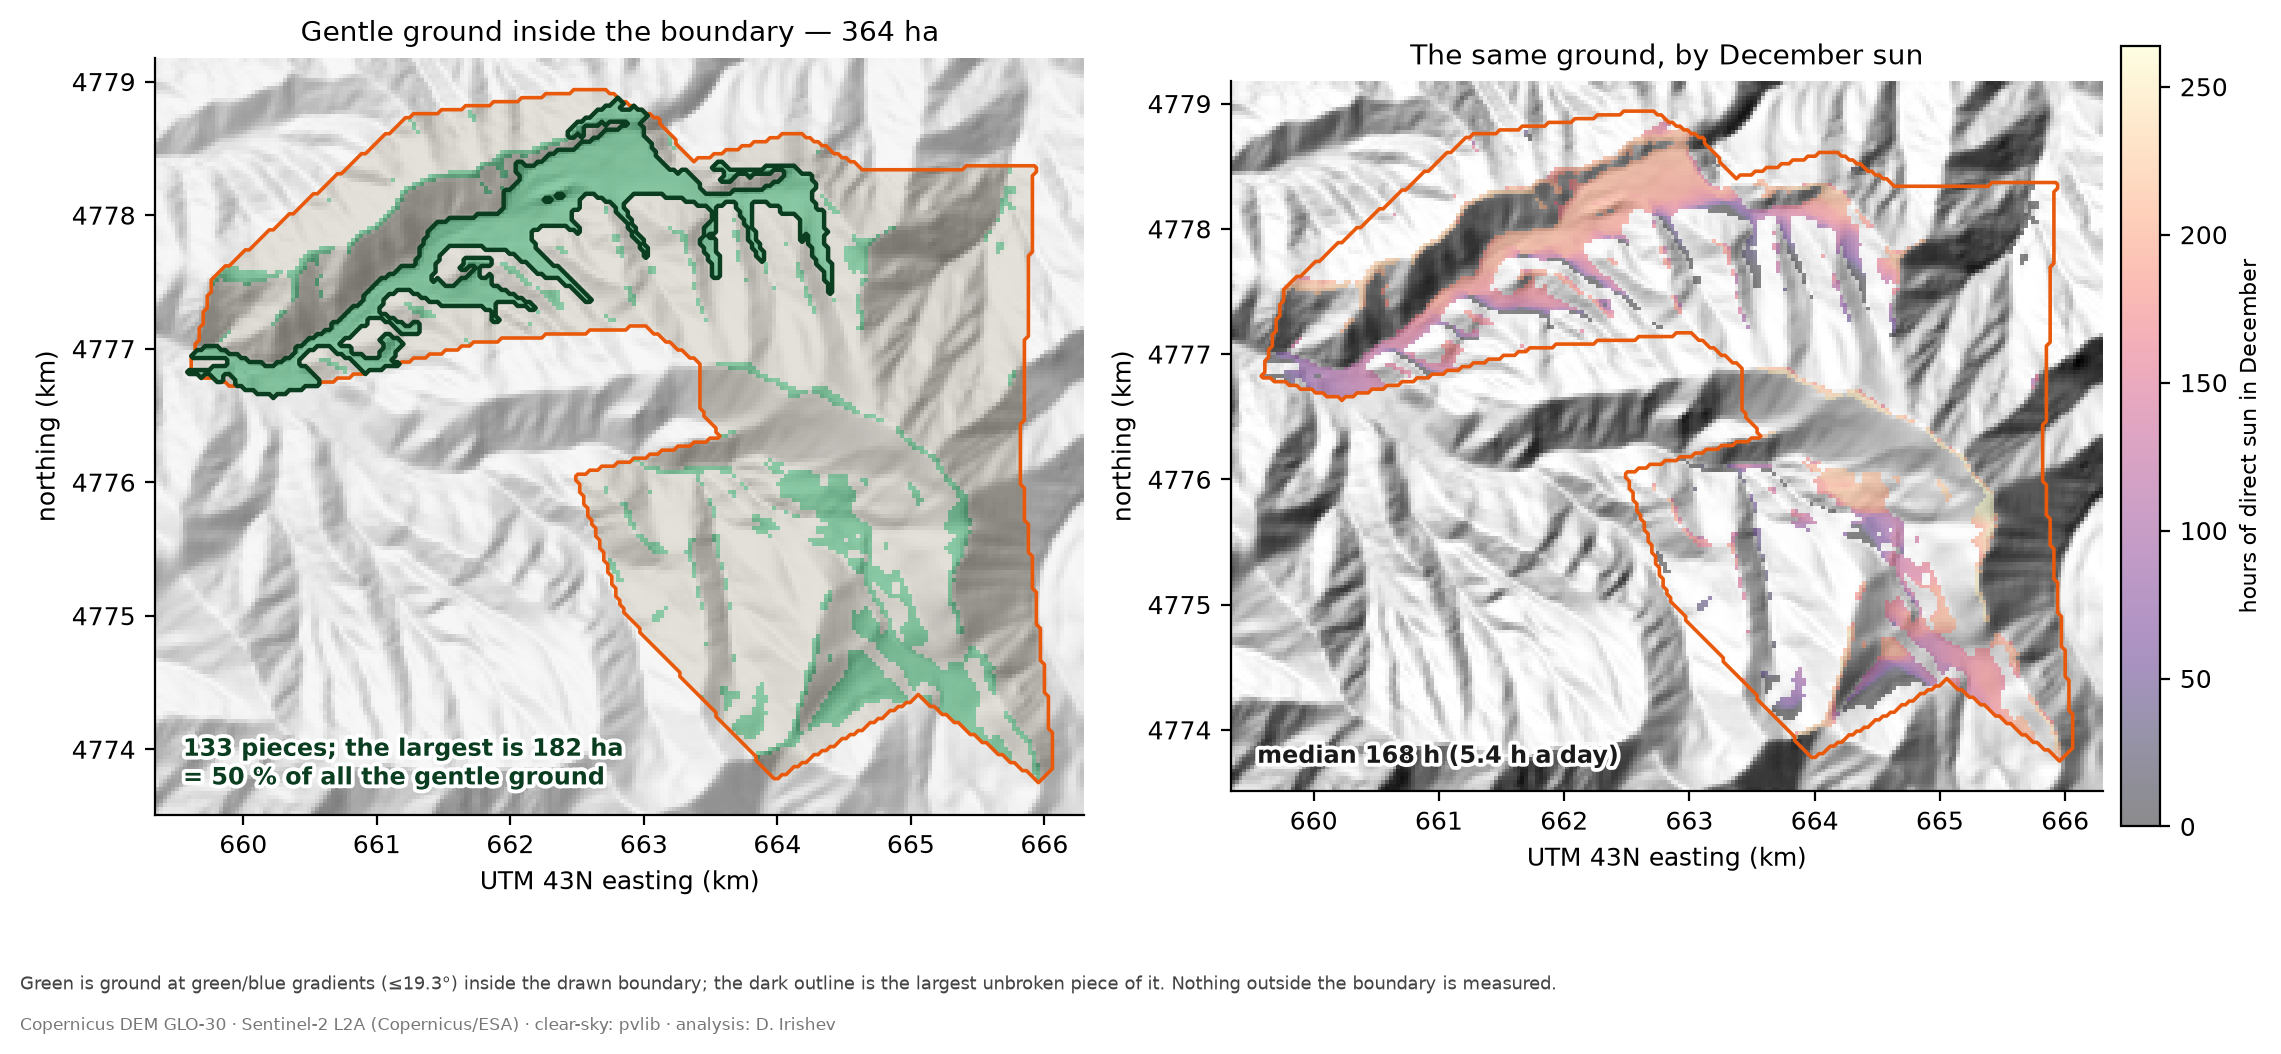

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/07_gentle_ground.png')

In [6]:
PL.figure_gentle_ground(dem, slope, mask)

## 4. The published mix of runs, against the gradients that exist

Two published sources disagree, so both are carried and every table names which
one it used. The operator's own general plan gives a four-way difficulty split;
press reporting of the April 2026 statement gave a round number. The plan
attaches its own 70 % to **snowmaking**, which is the most economical
explanation of where the press figure came from.

In [7]:
print(f"general plan : {PROJECT_LIFTS} lifts, "
      f"{100 * PROJECT_GREEN_BLUE_SHARE:.1f} % green+blue, "
      f"{100 * PROJECT_SNOWMAKING_SHARE:.0f} % snowmaking")
print(f"press        : {PROJECT_LIFTS_PRESS} lifts, "
      f"about {100 * PROJECT_GREEN_BLUE_SHARE_PRESS:.0f} % green+blue")
print()
print(PL.published_parameters().to_string(index=False))

general plan : 16 lifts, 60.9 % green+blue, 70 % snowmaking
press        : 17 lifts, about 70 % green+blue

                                       parameter                                published                      source
                                    piste length                                    60 km          both sources agree
                                           lifts                                       16       general plan, sheet 3
                                           lifts                                       17 press, April 2026 statement
                               cableways by POMA                                       11      statement, 18 Nov 2026
                             runs green and blue          60.9 % (10.6 green + 50.3 blue)       general plan, sheet 3
                              runs red and black           39.1 % (22.7 red + 16.4 black)       general plan, sheet 3
                             runs green and blue                  

In [8]:
grad = PL.gradients(slope, mask)
print(grad.pivot(index="gradient_class", columns="area", values="area_ha")
          .reindex([c[0] for c in ST.GRADIENT_CLASSES]).to_string())

area                   Drawn boundary
gradient_class                       
Beginner                         60.0
Novice                          141.0
Low intermediate                162.8
Intermediate                    105.0
Advanced intermediate           610.2
Expert                          696.4


In [9]:
gb_ha = float(cmp_df.green_blue_ha.iloc[0])
feas = PL.feasibility(gb_ha)
print(feas[["green_blue_source", "assumed_mean_piste_width_m", "green_blue_piste_ha",
            "available_green_blue_ha", "share_of_available_consumed"]].to_string(index=False))

                        green_blue_source  assumed_mean_piste_width_m  green_blue_piste_ha  available_green_blue_ha  share_of_available_consumed
general plan (10.6 % green + 50.3 % blue)                        30.0                109.6                    363.9                        0.301
general plan (10.6 % green + 50.3 % blue)                        40.0                146.2                    363.9                        0.402
general plan (10.6 % green + 50.3 % blue)                        50.0                182.7                    363.9                        0.502
             press statement (about 70 %)                        30.0                126.0                    363.9                        0.346
             press statement (about 70 %)                        40.0                168.0                    363.9                        0.462
             press statement (about 70 %)                        50.0                210.0                    363.9               

**The easy-terrain budget closes with room** — 30–50 % of available gentle
ground on the plan's own mix, 35–58 % on the press figure.

An earlier draft of this project put the same arithmetic at up to **101 %** and
concluded that easy terrain was the binding constraint. That figure combined the
superseded footprint with the conflated 70 %, and it is **withdrawn**
(`METHODS.md` §31). What a 30 m DEM still cannot show is whether two gentle
benches can be joined by a lift. That is a survey question.

## 5. Sun inside the boundary

Energy and duration answer different questions, and for a December launch the
one that matters is *hours of direct sun on the ground people ski on*.

In [10]:
sun = PL.sun(mask, slope)
print(sun.to_string(index=False))

   month  days  median_sun_h  median_h_per_day  p10_sun_h  p90_sun_h  median_sun_h_green_blue  median_h_per_day_green_blue  median_total_kwh_m2  median_shaded_fraction
November    30         157.3              5.24        0.2      233.5                    204.0                         6.80                 53.9                   0.454
December    31         110.2              3.56        0.0      212.8                    167.7                         5.41                 29.6                   0.591
 January    31         138.5              4.47        0.0      228.0                    190.5                         6.15                 42.6                   0.514
February    28         188.4              6.73       57.8      243.3                    223.5                         7.98                 80.6                   0.353
   March    31         274.3              8.85      201.2      318.3                    300.7                         9.70                154.4                 

The important column is the last pair. **The median pixel sees 3.6 h of direct
sun a day in December and the bottom tenth sees none — but the green and blue
ground sees 5.4 h.** The plateau faces the city, which is north; the gentle
shelves that would carry beginner runs are not the north-facing part of it.

That inverts an earlier reading of this site, which took the whole area's
December median as the number a beginner area would live with.

## 6. Snow, and the snow record's own blind spot

A pixel needs four cloud- and shadow-free observations before it enters a monthly
map. Shaded ground fails that test more often, so in mid-winter the pixels that
survive are the sunniest and flattest — and the median then describes *that
ground*, not the site. The bias columns measure it instead of leaving it to a
caveat.

In [11]:
snow, ctx = PL.snow(poly, dem, slope)
print(snow.to_string(index=False))

   month  dates  qualifying_share  median_valid_obs  median_snow_frequency  dec_insolation_bias_kwh  slope_bias_deg
November     24             0.768                17                  0.884                     19.9            -2.4
December     16             0.519                 5                  1.000                     42.5            -4.0
 January     16             0.596                 9                  1.000                     34.9            -3.6
February     13             0.922                11                  1.000                      5.1            -0.7
   March     25             0.979                24                  1.000                      1.4            -0.2
   April     17             0.940                14                  0.875                      3.9            -0.5


March is sound: 97.9 % of the area qualifies on a median of 24 observations with
a bias near zero. **December is not**: barely half the area qualifies, on a
median of 5 observations, and those pixels are ~43 kWh/m² sunnier and 4° flatter
than the site. The December snow figure is real, but it is a figure about the
sunnier half of the boundary and is labelled as such everywhere it appears.

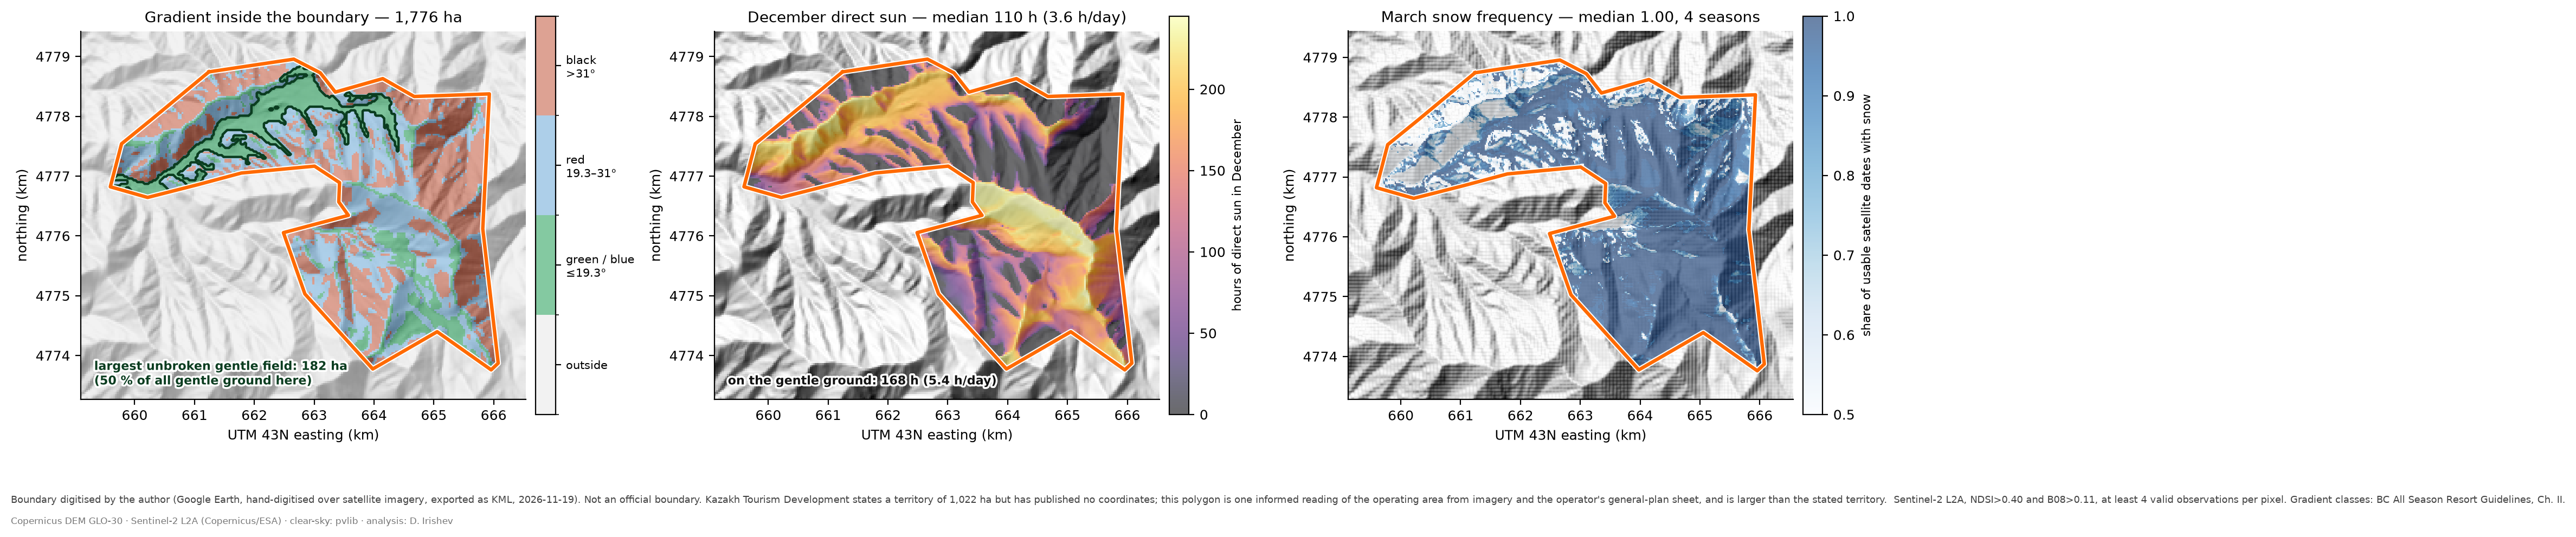

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/06_operating_area.png')

In [12]:
PL.figure(poly, props, dem, slope, mask, ctx)

## 7. What this notebook supersedes

| earlier claim | where it was | status |
|---|---|---|
| the 69 km² rectangle is the study area | nb 01–03, 1st release | **withdrawn** — wrong place, misses 3 of 7 control points |
| the 125 km² control-point envelope is the study area | nb 01–03, 2nd release | **withdrawn** — right place, but 86 % of it is not the site |
| the stated 1,022 ha, reconstructed as footprints A and B | nb 05 §1–§3 | **deleted** — `footprint.py` is gone; neither was the operating area |
| green/blue runs need up to 101 % of available ground | nb 05 §2 | **withdrawn** — 30–50 % here |
| gentle ground exists but is not in one place | nb 05 §1 | **withdrawn** — half of it is one 182 ha field |
| placement moves December sun by 3.9× | nb 05 §3 | **withdrawn** — it measured the gap between two inventions |
| 17 lifts, about 70 % green and blue | press, April 2026 | superseded by the general plan; both carried |

Notebook 04 (the 404 km² cluster) is unaffected: it never depended on where
this boundary is drawn. Notebook 05 now tests this boundary rather than a
reconstruction — its three-area comparison uses the drawn polygon as the Kok
Zhailau reference, and its DEM propagation check runs on the window around it.

## 8. Outputs

Everything on this page is written by one command:

```bash
KZ_AREA=superski python src/pipeline_operating_area.py
```

In [13]:
print(f"tables  -> {OUT_TAB}")
for p in sorted(OUT_TAB.glob("operating_area_*.csv")) + sorted(OUT_TAB.glob("published_*.csv")):
    print(f"   {p.name:46s} {p.stat().st_size/1024:6.1f} KB")
print(f"\nfigures -> {OUT_PNG}")
for p in sorted(OUT_PNG.glob("*.png")):
    print(f"   {p.name:46s} {p.stat().st_size/1e6:6.2f} MB")
print(f"\nboundary -> qgis/operating_area.geojson  ({int(summary['n_vertices'])} vertices)")

tables  -> /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/tables
   operating_area_gradient_classes.csv               0.5 KB
   operating_area_piste_feasibility.csv              0.6 KB
   operating_area_snow_by_month.csv                  0.3 KB
   operating_area_summary.csv                        0.7 KB
   operating_area_sun_by_month.csv                   0.5 KB
   operating_area_terrain.csv                        0.3 KB
   published_project_parameters.csv                  0.9 KB

figures -> /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png
   06_operating_area.png                            1.19 MB
   07_gentle_ground.png                             0.41 MB

boundary -> qgis/operating_area.geojson  (24 vertices)
